# Training and evaluating a classifier properly

**Module 02 — Fundamentals of AI, ML and Deep Learning Security**

A model is an artefact produced by an optimisation, and every security question about it ("what does
it memorise?", "what happens off-distribution?") starts with understanding what that optimisation
produced. This notebook builds one small model and evaluates it the way the rest of the course
expects: with a held-out split, per-class metrics, a confusion matrix, and a calibration check.

## Learning objectives

1. Train a classifier with a fixed seed and reproduce identical metrics on a second run.
2. Read precision, recall and a confusion matrix, and explain why accuracy alone is misleading.
3. Check calibration and explain what a confidence score does and does not mean.
4. Identify the three numbers a model card must report before anyone can assess its risk.

## Background

Supervised training minimises an average loss over a training set. Nothing in that objective mentions
the test set, the deployment distribution, or an adversary. Everything that follows in this course —
evasion, poisoning, leakage — exploits the gap between "minimises training loss" and "behaves as
intended in production".

The dataset used here ships with scikit-learn (a copy of the Wisconsin diagnostic measurements), so
no download and no network access are involved.

## Dependencies and installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "scikit-learn>=1.4" "matplotlib>=3.9"
```

CPU only. Runtime is a few seconds; there are no GPU requirements.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    brier_score_loss,
    classification_report,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 7
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print(f"{X.shape[0]} rows, {X.shape[1]} features, classes {list(data.target_names)}")
X.head(3)

569 rows, 30 features, classes [np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


**Expected output** — 569 rows and 30 features, and a three-row preview of the feature table. The
`target` column is 0 for malignant and 1 for benign in this copy of the data.

### Step 1 — Split before you look at anything else

The split is stratified so both classes appear in the same proportion in train and test. The seed is
fixed so the split — and therefore every metric after it — is reproducible.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

print("train", X_train.shape, "positive rate", round(float(y_train.mean()), 3))
print("test ", X_test.shape, "positive rate", round(float(y_test.mean()), 3))

train (426, 30) positive rate 0.627
test  (143, 30) positive rate 0.629


**Expected output** — 426 training rows and 143 test rows, with a positive rate near 0.63 in both.
If the two rates differed materially, the split would be misleading before a single model was fitted.

### Step 2 — Train, and note what the default settings decide for you

`max_iter=1000` is raised only so the solver converges quietly. Everything else is a default, which
is worth remembering: defaults are design decisions someone else made.

In [3]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
model.fit(X_train, y_train)

proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"accuracy {accuracy_score(y_test, pred):.3f}")
print(f"roc auc  {roc_auc_score(y_test, proba):.3f}")
print(f"brier    {brier_score_loss(y_test, proba):.3f}")

accuracy 0.979
roc auc  0.999
brier    0.017


**Expected output** (your values should match to three decimals)

```text
accuracy 0.979
roc auc  0.999
brier    0.017
```

Three numbers, three different questions: accuracy asks *how often right at this threshold*, AUC asks
*how well the scores rank*, Brier asks *how honest the probabilities are*.

### Step 3 — Per-class metrics, because the classes are not equally costly

A false negative (missing a malignancy) and a false positive (an unnecessary biopsy) have different
consequences. Aggregate accuracy hides which one you are making.

              precision    recall  f1-score   support

   malignant      0.963     0.981     0.972        53
      benign      0.989     0.978     0.983        90

    accuracy                          0.979       143
   macro avg      0.976     0.979     0.978       143
weighted avg      0.979     0.979     0.979       143



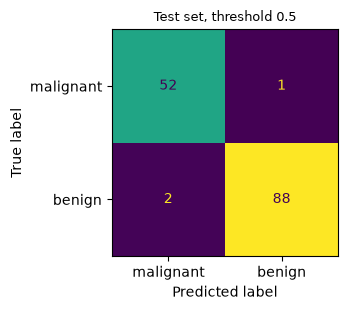

In [4]:
print(
    classification_report(
        y_test, pred, target_names=["malignant", "benign"], digits=3
    )
)

fig, ax = plt.subplots(figsize=(3.6, 3.2))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["malignant", "benign"], ax=ax, colorbar=False
)
ax.set_title("Test set, threshold 0.5", fontsize=9)
plt.tight_layout()
plt.show()

**Expected output** — a report with precision/recall near 0.95–0.99 for both classes, and a 2×2 matrix.
Read the off-diagonal cells: those are the errors you would have to explain to a clinician, and they
are the only cells an attacker needs to move.

### Step 4 — Calibration: what "0.9" actually means

If the model says 0.9 for a hundred patients, roughly ninety should be benign. Calibration is the
property that makes a confidence score usable — and, as Module 09 shows, it is also the property that
leaks membership information.

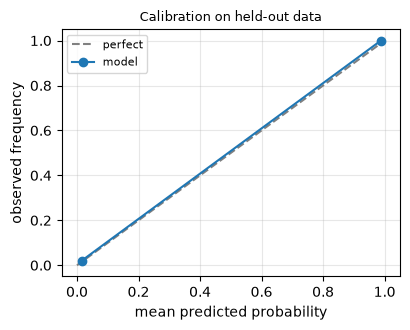

,bin,n,mean_confidence,observed_rate
0,0.0-0.2,51,0.015,0.02
1,0.8-1.0,84,0.988,1.00


In [5]:
bins = np.linspace(0, 1, 6)
idx = np.digitize(proba, bins) - 1
rows = []
for b in range(len(bins) - 1):
    mask = idx == b
    if mask.sum() >= 10:
        rows.append(
            {
                "bin": f"{bins[b]:.1f}-{bins[b+1]:.1f}",
                "n": int(mask.sum()),
                "mean_confidence": round(float(proba[mask].mean()), 3),
                "observed_rate": round(float(y_test.to_numpy()[mask].mean()), 3),
            }
        )
calibration = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(4.2, 3.4))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
ax.plot(calibration.mean_confidence, calibration.observed_rate, "o-", label="model")
ax.set_xlabel("mean predicted probability")
ax.set_ylabel("observed frequency")
ax.set_title("Calibration on held-out data", fontsize=9)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

calibration

**Expected output** — points close to the diagonal, i.e. a reasonably calibrated model on this data.
Note the small bins at the extremes: with 143 test rows, a bin with 9 patients cannot support a strong
claim, which is why the table prints `n` next to every rate.

### Step 5 — Reproducibility check

A result you cannot reproduce is not a result. Refitting with the same seed must give identical
predictions; refitting with a different seed should give slightly different ones.

In [6]:
model_again = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)
).fit(X_train, y_train)
repeat = model_again.predict_proba(X_test)[:, 1]
max_repeat_delta = float(np.abs(repeat - proba).max())

other = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED + 1)
).fit(X_train, y_train)
max_seed_delta = float(np.abs(other.predict_proba(X_test)[:, 1] - proba).max())

print(f"same seed, largest probability difference: {max_repeat_delta:.2e}")
print(f"different seed, largest probability difference: {max_seed_delta:.4f}")
assert max_repeat_delta < 1e-9, "the same seed must reproduce the same model"

same seed, largest probability difference: 0.00e+00
different seed, largest probability difference: 0.0000


**Expected output** — a same-seed difference of `0.00e+00` (bitwise identical in practice) and a change of
well under 0.01 for the different seed. The assertion is the important line: it converts "should be
deterministic" into a test, and a machine that fails it is a machine whose results you cannot publish.

## Exercises

1. **Move the threshold.** Use 0.2 instead of 0.5 and report the change in recall for the malignant
   class. Which error did you trade away?
2. **Break the split.** Split *without* `stratify` and without a fixed seed, run it five times, and
   record the spread in accuracy. What does that spread tell you about single-run claims?
3. **Add a slice.** Create a binary feature from `mean radius` (above/below the median) and compute
   accuracy separately for each slice. Are the errors evenly distributed?
4. **Compute the security-relevant number.** Take the confusion matrix and state, in one sentence,
   how many test records an attacker would need to flip to move accuracy by one point.

## Reflection questions

1. Accuracy, AUC and Brier answer different questions. Which one would you put on a model card for a
   clinician, and which would you keep internal? Why?
2. The model has no idea which records are in its training set. Why, then, can it leak that information
   (Module 09)?
3. Everything here assumes the test set resembles deployment. Name two realistic ways that assumption
   fails for a hospital deploying this model.

## References

1. scikit-learn documentation, *Metrics and scoring* and *Probability calibration*.
2. Guo, C. et al., "On Calibration of Modern Neural Networks", ICML 2017.
3. Mitchell, M. et al., "Model Cards for Model Reporting", FAT* 2019.
4. NIST, *AI RMF 1.0*, NIST AI 100-1, 2023 — Measure function.